# Fire stream (NASA VIIRS): Person C
Turns the NASA FIRMS fire points into daily fire features per city (one row per city per day).
Only 2022 and 2023 are used. The 2024 files are kept sealed for the Week 14 extension and are never read here.
Every removal of data is also written down in `DECISIONS.md`.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.append(str(ROOT))

from src.config import CITY_COUNTRY, CITY_COORDS, NASA_FILES, nasa_path, TRAIN_START, TRAIN_END

OUT_DIR = ROOT / "Dataset" / "Exported_Fire"
OUT_DIR.mkdir(parents=True, exist_ok=True)

START, END = pd.Timestamp("2022-01-01"), pd.Timestamp("2023-12-31")   # same window as AQ and weather
RADII_KM = [50, 100, 150, 200, 300]
CONES = {"up30": (0, 30), "up45": (0, 45), "up60": (0, 60), "down45": (180, 45)}   # name: (offset from wind, half-angle)

audit = []   # one entry per filter step, copied into DECISIONS.md
def log_step(step, before, after, note=""):
    audit.append({"step": step, "rows_before": before, "rows_after": after,
                  "removed": before - after, "note": note})
    print(f"{step:45s} {before:>9,} -> {after:>9,}  (removed {before - after:,})")

**Setup.** Imports the shared settings from `src/config.py`. `NASA_FILES` lists only the 2022 and 2023 files, so 2024 cannot be loaded by mistake.
`CONES` holds the cone settings: three upwind half-angles (30, 45, 60 degrees) and one downwind placebo cone (wind direction + 180 degrees, 45 degrees wide).
`log_step` prints and stores the row count before and after every filter, for the bookkeeping file.

#### Step 1: Load and stack the 4 fire files

In [2]:
tables = []
for (country, year), name in NASA_FILES.items():
    # acq_time is text like "0833": read it as text, or the leading zero is lost
    df = pd.read_csv(ROOT / nasa_path(country, year), dtype={"acq_time": str})
    df["origin_country"] = country        # India file = IN, Pakistan file = PK
    df["source_file"] = name
    print(f"{name:26s} rows={len(df):8,}  first={df['acq_date'].min()}  last={df['acq_date'].max()}")
    tables.append(df)

fires_raw = pd.concat(tables, ignore_index=True)
print("\nTotal rows:", f"{len(fires_raw):,}")
print("Columns:", list(fires_raw.columns))
print("Duplicate points (same place, date and time):",
      fires_raw.duplicated(["latitude", "longitude", "acq_date", "acq_time"]).sum())
print("Satellites:", fires_raw["satellite"].value_counts().to_dict())
print("acq_time lengths:", fires_raw["acq_time"].str.len().value_counts().to_dict())

NASA - 2022 - India.csv    rows= 591,594  first=2022-01-01  last=2022-12-31


NASA - 2023 - India.csv    rows= 579,733  first=2023-01-01  last=2023-12-31
NASA - 2022.csv            rows=  60,973  first=2022-01-01  last=2022-12-31
NASA - 2023.csv            rows=  52,473  first=2023-01-01  last=2023-12-31



Total rows: 1,284,773
Columns: ['latitude', 'longitude', 'bright_ti4', 'scan', 'track', 'acq_date', 'acq_time', 'satellite', 'instrument', 'confidence', 'version', 'bright_ti5', 'frp', 'daynight', 'type', 'origin_country', 'source_file']


Duplicate points (same place, date and time): 0
Satellites: {'N': 1284773}
acq_time lengths: {4: 1284773}


**Load and stack.** Reads the 4 files and adds `origin_country` from the file each point came from. That column is what later separates cross-border (India) fires from local (Pakistan) fires.
Checks: there are no duplicate points, and every point comes from one satellite (NOAA-20, code `N`), so no fire is counted twice by two satellites. Every `acq_time` kept its 4 digits.

#### Step 2: Keep only the study area

In [3]:
# The India file covers all of India (down to 8 N). Keep a box around the 11 cities
# with roughly 300 km to spare on every side, which is our largest radius.
LAT_MIN, LAT_MAX, LON_MIN, LON_MAX = 26, 37, 68, 79
in_box = fires_raw["latitude"].between(LAT_MIN, LAT_MAX) & fires_raw["longitude"].between(LON_MIN, LON_MAX)
fires = fires_raw[in_box].copy()
log_step("Bounding box 26-37 N, 68-79 E", len(fires_raw), len(fires))
print(fires.groupby("origin_country").size())

Bounding box 26-37 N, 68-79 E                 1,284,773 ->   287,323  (removed 997,450)
origin_country
IN    185393
PK    101930
dtype: int64


**Study area.** Most of the India file is far from Punjab (southern and eastern India), so it is cut to a box around the 11 cities. The box is wide enough that every point within 300 km of a city is kept. The 300 km check comes in Step 6.

#### Step 3: Keep only vegetation fires (type 0)

In [4]:
print("Points by type before filtering:")
print(pd.crosstab(fires["type"], fires["origin_country"]))
before = len(fires)
fires = fires[fires["type"] == 0].copy()
log_step("Keep type 0 (vegetation fire)", before, len(fires), "drops type 2 static sources and type 3 offshore")

Points by type before filtering:
origin_country      IN     PK
type                         
0               182488  97480
2                 2891   4414
3                   14     36
Keep type 0 (vegetation fire)                   287,323 ->   279,968  (removed 7,355)


**Type filter.** NASA marks each point as 0 = vegetation fire, 2 = static land source (a hot spot that keeps returning to the same place: brick kilns, factories, flares), and 3 = offshore.
Our hypotheses are about crop burning, so only type 0 is kept.
Type 2 points burn at about the same rate every month, so they cannot explain day-to-day smog changes, and satellites only see the hottest kilns.
This removal is recorded in `DECISIONS.md`.

#### Step 4: Confidence filter (main version + two sensitivity versions)

In [5]:
month = pd.to_datetime(fires["acq_date"]).dt.month
print("Share of each confidence level by month (rows = month):")
print(pd.crosstab(month, fires["confidence"], normalize="index").round(2))
print("\nConfidence vs day/night:")
print(pd.crosstab(fires["confidence"], fires["daynight"]))

before = len(fires)
fires_nhl = fires.copy()                                  # sensitivity: everything, including low
fires = fires[fires["confidence"].isin(["n", "h"])].copy()  # MAIN version
fires_h = fires[fires["confidence"] == "h"].copy()        # sensitivity: high only
log_step("Keep confidence n and h (drop l)", before, len(fires), "main version")
print(f"Sensitivity versions kept: n+h+l = {len(fires_nhl):,} points, h only = {len(fires_h):,} points")

Share of each confidence level by month (rows = month):
confidence     h     l     n
acq_date                    
1           0.02  0.01  0.97
2           0.03  0.04  0.93
3           0.03  0.09  0.88
4           0.05  0.27  0.68
5           0.03  0.36  0.60
6           0.02  0.19  0.79
7           0.01  0.08  0.91
8           0.01  0.06  0.94
9           0.01  0.11  0.88
10          0.02  0.08  0.90
11          0.03  0.02  0.94
12          0.01  0.01  0.98

Confidence vs day/night:
daynight         D      N
confidence               
h             8459     75
l            41172      0
n           203671  26591


Keep confidence n and h (drop l)                279,968 ->   238,796  (removed 41,172)
Sensitivity versions kept: n+h+l = 279,968 points, h only = 8,534 points


**Confidence filter.** VIIRS gives every point a confidence code:
- `l` (low): daytime only, a weak heat signal, often sun glint or hot bare ground.
- `n` (nominal): a clear heat signal, the normal "real fire" case.
- `h` (high): the pixel is so hot the sensor saturates, which means a very intense fire.

The main version keeps `n` and `h`. Low-confidence points are common in April and May, when fields are hot and bare, and rare in October and November.
Two versions are kept for sensitivity checks: `n+h+l` and `h` only.

#### Step 5: Fix time (UTC to Pakistan time)

In [6]:
def to_local_date(df):
    # join date and 4-digit time into one UTC datetime, add 5 hours, THEN take the date
    utc = pd.to_datetime(df["acq_date"] + " " + df["acq_time"].str.zfill(4), format="%Y-%m-%d %H%M")
    df["time_utc"] = utc
    df["time_local"] = utc + pd.Timedelta(hours=5)
    df["date"] = df["time_local"].dt.normalize()
    return df

for name in ["fires", "fires_nhl", "fires_h"]:
    df = to_local_date(globals()[name])
    inside = df["date"].between(START, END)
    globals()[name] = df[inside].copy()
    if name == "fires":
        log_step("Drop points that fall on 2024-01-01 local time", len(df), int(inside.sum()),
                 "late 31 Dec 2023 UTC detections")

shifted = (fires["date"] != pd.to_datetime(fires["acq_date"])).sum()
print("Points whose local date differs from the UTC date:", f"{shifted:,}")
print("Local date range:", fires["date"].min().date(), "to", fires["date"].max().date())

Drop points that fall on 2024-01-01 local time   238,796 ->   238,756  (removed 40)


Points whose local date differs from the UTC date: 26,626
Local date range: 2022-01-01 to 2023-12-31


**Time.** NASA times are in UTC. The 5 hours are added to the full date and time *before* the date is taken. Shifting only the date column would put evening detections on the wrong day. This matches the AQ and weather notebooks.
A few detections on the evening of 31 Dec 2023 (UTC) fall on 1 Jan 2024 local time. They are outside our window and are dropped.

#### Step 6: 0/1 dummy columns for day/night and confidence

In [7]:
for df in (fires, fires_nhl, fires_h):
    df["is_night"] = (df["daynight"] == "N").astype(int)    # reference: day
    df["conf_high"] = (df["confidence"] == "h").astype(int)  # reference: nominal (or low)
    df["conf_low"] = (df["confidence"] == "l").astype(int)
print(fires[["daynight", "is_night", "confidence", "conf_high"]].drop_duplicates().sort_values(["is_night", "conf_high"]))

       daynight  is_night confidence  conf_high
38            D         0          n          0
126           D         0          h          1
387           N         1          n          0
265626        N         1          h          1


**Dummy encoding.** `daynight` and `confidence` are text categories. They become 0/1 columns, leaving out one reference level each: day for `daynight`, nominal for confidence. These are point-level columns. The daily tables use counts and FRP instead.

#### Step 7: Distance and bearing from every city to every fire

In [8]:
EARTH_R_KM = 6371.0

def haversine_km(lat1, lon1, lat2, lon2):
    """Great-circle distance in km. Works on whole numpy arrays at once."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    return 2 * EARTH_R_KM * np.arcsin(np.sqrt(a))

def bearing_deg(lat1, lon1, lat2, lon2):
    """Compass bearing FROM point 1 TO point 2: 0 = north, 90 = east."""
    lat1, lon1, lat2, lon2 = map(np.radians, (lat1, lon1, lat2, lon2))
    x = np.sin(lon2 - lon1) * np.cos(lat2)
    y = np.cos(lat1) * np.sin(lat2) - np.sin(lat1) * np.cos(lat2) * np.cos(lon2 - lon1)
    return (np.degrees(np.arctan2(x, y)) + 360) % 360

# toy checks: a point due north has bearing 0, due east about 90
assert abs(bearing_deg(31, 74, 32, 74) - 0) < 1e-6
assert abs(bearing_deg(31, 74, 31, 75) - 90) < 1
assert abs(haversine_km(31, 74, 32, 74) - 111.2) < 0.5

def city_fire_pairs(df, max_km=max(RADII_KM)):
    """One row per (city, fire) pair within max_km. Loops over the 11 cities, not over fires."""
    out = []
    lat, lon = df["latitude"].to_numpy(), df["longitude"].to_numpy()
    for city, (clat, clon) in CITY_COORDS.items():
        dist = haversine_km(clat, clon, lat, lon)
        near = dist <= max_km
        part = df.loc[near, ["date", "origin_country", "frp", "confidence"]].copy()
        part.insert(0, "city", city)
        part["dist_km"] = dist[near]
        part["bearing_deg"] = bearing_deg(clat, clon, lat[near], lon[near])
        out.append(part)
    return pd.concat(out, ignore_index=True)

pairs_nhl = city_fire_pairs(fires_nhl)      # all confidence levels; the other versions are filters of this
pairs = pairs_nhl[pairs_nhl["confidence"].isin(["n", "h"])].copy()
pairs_h = pairs_nhl[pairs_nhl["confidence"] == "h"].copy()
print("City-fire pairs within 300 km (main version):", f"{len(pairs):,}")

print("\nFires within 150 km and 300 km of each city, by origin (main version):")
check = pd.concat({r: pairs[pairs["dist_km"] <= r].groupby(["city", "origin_country"]).size().unstack(fill_value=0)
                   for r in (150, 300)}, axis=1).reindex(list(CITY_COORDS)).fillna(0).astype(int)
print(check)

City-fire pairs within 300 km (main version): 1,422,843

Fires within 150 km and 300 km of each city, by origin (main version):
                   150            300       
origin_country      IN     PK      IN     PK
city                                        
Lahore           61873  28523  125479  52819
Faisalabad        8108  39277   97859  65337
Multan               0  18414   16007  55248
Rawalpindi        1882  10884   17394  46112
Sialkot          24421  20061  105779  49145
Rahim Yar Khan      79   8425    3232  22740
Islamabad         1779  10338   14967  45092
Amritsar         66170  20462  129160  48181
Ferozepur        87790  19343  131143  49195
Ludhiana        105121    786  142361  31930
Jalandhar        91341   5683  137942  35721


**Distance and bearing.** For each city, the Haversine formula gives the distance to every fire, and `atan2` gives the compass bearing from the city to the fire. Both are computed for all fires at once (vectorised), one city at a time. Everything within 300 km is kept, so every smaller radius is just a filter on this table.
One fire can belong to several cities, which is correct: its smoke can reach any of them.

The table shows that India-origin fires within 150 km exist mainly for Lahore, Sialkot and Faisalabad. Multan and Rahim Yar Khan have essentially none, and Islamabad and Rawalpindi very few. That is why the 300 km radius is also kept.

#### Step 8: The cone function, tested on toy cases

In [9]:
def angle_diff(a, b):
    """Smallest difference between two compass angles, 0 to 180. 350 and 10 are 20 apart."""
    return np.abs((np.asarray(a) - np.asarray(b) + 180) % 360 - 180)

def cone_mask(bearing, wind_from, half_angle, offset=0):
    """True if a fire lies inside the cone.
    wind_from: Open-Meteo wind direction = where the wind comes FROM, so upwind fires lie at that bearing.
    offset=0 gives the upwind cone, offset=180 the downwind (placebo) cone."""
    return angle_diff(bearing, (np.asarray(wind_from) + offset) % 360) <= half_angle

# toy checks
assert angle_diff(350, 10) == 20 and angle_diff(10, 350) == 20 and angle_diff(0, 180) == 180
assert cone_mask(0, 0, 45)              # wind from north -> fire to the north is upwind
assert not cone_mask(180, 0, 45)        # wind from north -> fire to the south is not
assert cone_mask(180, 0, 45, offset=180)  # ...but it is in the downwind cone
assert cone_mask(350, 10, 30) and not cone_mask(350, 10, 15)   # wrap-around across 0/360
assert cone_mask(44, 0, 45) and not cone_mask(46, 0, 45)
print("All cone toy checks passed")

All cone toy checks passed


**Cone function.** A fire is upwind when its bearing from the city is within the half-angle of the direction the wind comes from. Open-Meteo reports where the wind comes *from*.
The difference between two angles is taken around the circle, so 350 and 10 degrees count as 20 apart, not 340.
The checks above confirm both rules, and the downwind version (direction + 180 degrees).

#### Step 9: Daily radius features on the full city-day grid

In [10]:
CITIES = list(CITY_COORDS)
DATES = pd.date_range(START, END, freq="D")
GRID = pd.MultiIndex.from_product([CITIES, DATES], names=["city", "date"])
print("Grid rows (11 cities x days):", len(GRID))

def daily_counts(p, cone_name):
    """Fire count and FRP sum per city-day, for every radius and origin (IN, PK, ALL). Long format."""
    rows = []
    for r in RADII_KM:
        sub = p[p["dist_km"] <= r]
        for origin in ["IN", "PK", "ALL"]:
            s = sub if origin == "ALL" else sub[sub["origin_country"] == origin]
            g = s.groupby(["city", "date"]).agg(fire_count=("frp", "size"), frp_sum_mw=("frp", "sum"))
            g = g.reindex(GRID, fill_value=0).reset_index()      # no fires that day -> 0, never missing
            g["radius_km"], g["origin"], g["cone"] = r, origin, cone_name
            rows.append(g)
    return pd.concat(rows, ignore_index=True)

long_radius = daily_counts(pairs, "none")
long_radius["fire_count"] = long_radius["fire_count"].astype(int)
print("Long radius table:", long_radius.shape)
print("Missing values:", long_radius.isna().sum().sum())

Grid rows (11 cities x days): 8030


Long radius table: (120450, 7)
Missing values: 0


**Radius features.** For every city, day, radius (50 to 300 km) and origin (India, Pakistan, both), this counts the fires and adds up their fire radiative power (FRP, in megawatts, a measure of fire intensity).
The table starts from a complete grid of 11 cities x 730 days = 8,030 city-days. A day without fires gets 0, never a missing value.

#### Step 10: Cone features (uses Person B's daily wind table)

In [11]:
# Person B's daily wind table (weather.ipynb). wind_dir_daily_deg = vector-mean direction the wind
# came FROM; stagnant = 1 when the daily vector-mean wind is below 2 km/h.
WIND_FILE = ROOT / "Dataset" / "clean" / "wind_daily.parquet"
wind = pd.read_parquet(WIND_FILE)
wind["date"] = pd.to_datetime(wind["date"]).dt.normalize()
wind = wind.rename(columns={"wind_dir_daily_deg": "wind_dir_from_deg"})
assert not wind.duplicated(["city", "date"]).any()
assert set(wind["city"]) == set(CITIES)

has_wind = pd.Series(True, index=pd.MultiIndex.from_frame(wind[["city", "date"]])).reindex(GRID, fill_value=False)
print("City-days with a daily wind value:", int(has_wind.sum()), "of", len(GRID))
print("City-days without wind (cone features left empty):")
print(has_wind[~has_wind].reset_index().groupby("city")["date"].agg(["min", "max", "count"]))
print("Stagnant share of city-days:", round(wind["stagnant"].mean(), 3))

def cone_counts(p, wind):
    """Long-format counts for every cone. On stagnant days the cone keeps every fire (= radius count).
    City-days without a wind value get empty (NaN) cone counts, not 0."""
    p = p.merge(wind[["city", "date", "wind_dir_from_deg", "stagnant"]], on=["city", "date"], how="inner")
    out = []
    for name, (offset, half) in CONES.items():
        keep = cone_mask(p["bearing_deg"], p["wind_dir_from_deg"], half, offset) | (p["stagnant"] == 1)
        out.append(daily_counts(p[keep], name))
    long = pd.concat(out, ignore_index=True)
    no_wind = ~has_wind.reindex(pd.MultiIndex.from_frame(long[["city", "date"]])).to_numpy()
    long.loc[no_wind, ["fire_count", "frp_sum_mw"]] = np.nan
    return long

long_cone = cone_counts(pairs, wind)
stagnant = wind.set_index(["city", "date"])["stagnant"].reindex(GRID)
print("Cone table:", long_cone.shape)

# checks: a cone can never hold more fires than the full circle, and wider cones hold at least as many
chk = pd.concat([long_radius, long_cone]).pivot_table(
    index=["city", "date", "radius_km", "origin"], columns="cone", values="fire_count")
for c in CONES:
    assert (chk[c].dropna() <= chk.loc[chk[c].notna(), "none"]).all(), c
w_rows = chk.dropna(subset=list(CONES))          # skip the January 2022 days without wind
assert (w_rows["up30"] <= w_rows["up45"]).all() and (w_rows["up45"] <= w_rows["up60"]).all()
stag_days = stagnant[stagnant == 1].index
assert (chk.loc[chk.index.droplevel([2, 3]).isin(stag_days), "up45"]
        == chk.loc[chk.index.droplevel([2, 3]).isin(stag_days), "none"]).all()
print("Cone checks passed")

City-days with a daily wind value: 7852 of 8030
City-days without wind (cone features left empty):
                      min        max  count
city                                       
Amritsar       2022-01-01 2022-01-29     29
Faisalabad     2022-01-01 2022-01-11     11
Ferozepur      2022-01-01 2022-01-29     29
Islamabad      2022-01-01 2022-01-11     11
Jalandhar      2022-01-01 2022-01-29     29
Lahore         2022-01-01 2022-01-11     11
Ludhiana       2022-01-01 2022-01-14     14
Multan         2022-01-01 2022-01-11     11
Rahim Yar Khan 2022-01-01 2022-01-11     11
Rawalpindi     2022-01-01 2022-01-11     11
Sialkot        2022-01-01 2022-01-11     11
Stagnant share of city-days: 0.107


Cone table: (481800, 7)


Cone checks passed


**Cone features.** This uses the daily wind direction from Person B's weather table: the vector mean of the day's hourly winds, which is where the wind came *from*. It counts the fires inside each cone (30, 45 and 60 degrees upwind, plus the 45 degree downwind placebo).
On **stagnant days**, when there is almost no net wind, the daily direction is meaningless, so the cone keeps every fire in the radius and the `stagnant` flag marks those days. Leaving those days empty would drop the worst smog days later.
The wind table starts on 12 January 2022 for the Pakistani cities and on 15–30 January 2022 for the Indian cities, because the weather files start then. On those few January city-days there is no wind direction, so the cone counts are left **empty** rather than set to 0 (the radius counts are still complete). This is months before the modelling window starts (4 August 2022).
The checks confirm that no cone ever holds more fires than the full circle, that wider cones always hold at least as many as narrower ones, and that on stagnant days the cone count equals the radius count.

#### Step 11: Long and wide daily tables

In [12]:
fire_long = pd.concat([long_radius] + ([long_cone] if long_cone is not None else []), ignore_index=True)
fire_long.insert(1, "country", fire_long["city"].map(CITY_COUNTRY))
fire_long = fire_long[["city", "country", "date", "cone", "radius_km", "origin", "fire_count", "frp_sum_mw"]]

def wide_from(long, cone, radius, prefix):
    """One column per origin for count and FRP, e.g. fire_cnt_r150_in."""
    s = long[(long["cone"] == cone) & (long["radius_km"] == radius)]
    w = s.pivot_table(index=["city", "date"], columns="origin", values=["fire_count", "frp_sum_mw"])
    w.columns = [f"{'fire_cnt' if v == 'fire_count' else 'fire_frp'}_{prefix}_{o.lower()}" for v, o in w.columns]
    return w.reindex(GRID)

# default setting: 150 km, no cone + 45 degree upwind cone + downwind placebo
parts = [wide_from(fire_long, "none", 150, "r150"),
         wide_from(fire_long, "up45", 150, "up45_r150"),
         wide_from(fire_long, "down45", 150, "down45_r150")]
# confidence sensitivity versions, 150 km, no cone
parts += [wide_from(daily_counts(pairs_h[pairs_h["dist_km"] <= 150], "none"), "none", 150, "r150_conf_h"),
          wide_from(daily_counts(pairs_nhl[pairs_nhl["dist_km"] <= 150], "none"), "none", 150, "r150_conf_nhl")]
fire_wide = pd.concat(parts, axis=1)
fire_wide["stagnant"] = stagnant
fire_wide = fire_wide.reset_index()
fire_wide.insert(1, "country", fire_wide["city"].map(CITY_COUNTRY))
cnt_cols = [c for c in fire_wide.columns if c.startswith("fire_cnt")]
fire_wide[cnt_cols] = fire_wide[cnt_cols].round().astype("Int64")   # Int64 keeps the empty no-wind cone days
fire_wide["stagnant"] = fire_wide["stagnant"].astype("Int64")

print("Long table:", fire_long.shape, "  Wide table:", fire_wide.shape)
print(fire_wide.columns.tolist())

Long table: (602250, 8)   Wide table: (8030, 34)
['city', 'country', 'date', 'fire_cnt_r150_all', 'fire_cnt_r150_in', 'fire_cnt_r150_pk', 'fire_frp_r150_all', 'fire_frp_r150_in', 'fire_frp_r150_pk', 'fire_cnt_up45_r150_all', 'fire_cnt_up45_r150_in', 'fire_cnt_up45_r150_pk', 'fire_frp_up45_r150_all', 'fire_frp_up45_r150_in', 'fire_frp_up45_r150_pk', 'fire_cnt_down45_r150_all', 'fire_cnt_down45_r150_in', 'fire_cnt_down45_r150_pk', 'fire_frp_down45_r150_all', 'fire_frp_down45_r150_in', 'fire_frp_down45_r150_pk', 'fire_cnt_r150_conf_h_all', 'fire_cnt_r150_conf_h_in', 'fire_cnt_r150_conf_h_pk', 'fire_frp_r150_conf_h_all', 'fire_frp_r150_conf_h_in', 'fire_frp_r150_conf_h_pk', 'fire_cnt_r150_conf_nhl_all', 'fire_cnt_r150_conf_nhl_in', 'fire_cnt_r150_conf_nhl_pk', 'fire_frp_r150_conf_nhl_all', 'fire_frp_r150_conf_nhl_in', 'fire_frp_r150_conf_nhl_pk', 'stagnant']


**Two daily tables.**
- `fire_long` holds every setting (cone x radius x origin). It is used for the cone and radius sensitivity analysis.
- `fire_wide` is one row per city per day with the default setting (150 km), ready to merge with AQ and weather on `city` + `date`. It holds the 150 km no-cone counts, the ±45° upwind and downwind cone counts, the two confidence sensitivity versions at 150 km, and Person B's `stagnant` flag (so the merge can tell which cone counts are really radius counts).

Lags (1 to 3 days) are not added here. They are added after the merge, grouped by city.

#### Step 12: Summary statistics for the default fire features

In [13]:
key_cols = ["fire_cnt_r150_in", "fire_cnt_r150_pk", "fire_cnt_r150_all",
            "fire_frp_r150_in", "fire_frp_r150_pk", "fire_frp_r150_all",
            "fire_cnt_up45_r150_in", "fire_cnt_down45_r150_in"]
kw = fire_wide[key_cols].astype(float)   # nullable ints -> float; NaN = no wind (January 2022 cone days)
summary = pd.DataFrame({
    "mean": kw.mean(),
    "median": kw.median(),
    "sd": kw.std(),
    "iqr": kw.quantile(0.75) - kw.quantile(0.25),
    "skewness": kw.skew(),
    "share_zero_days": (kw == 0).sum() / kw.notna().sum(),
}).round(2)
print("All 11 cities, 2022-01-01 to 2023-12-31, 150 km (cone columns skip the January 2022 days without wind):")
print(summary)

octnov = kw[fire_wide["date"].dt.month.isin([10, 11])]
print("\nSame, Oct-Nov only (rice-burning season):")
print(octnov.agg(["mean", "median", "std"]).T.round(2))

# how much of the circle each cone keeps: Pakistani cities, Oct-Nov, 150 km, India-origin fires
sel = fire_long[(fire_long["country"] == "PK") & (fire_long["radius_km"] == 150) & (fire_long["origin"] == "IN")
                & fire_long["date"].dt.month.isin([10, 11])]
cone_table = sel.groupby("cone")["fire_count"].agg(
    mean_per_day="mean", median_per_day="median", share_zero_days=lambda s: (s == 0).mean(),
    total="sum").reindex(["none", "up60", "up45", "up30", "down45"])
cone_table["share_of_circle"] = cone_table["total"] / cone_table.loc["none", "total"]
print("\nIndia-origin fires within 150 km of the 7 Pakistani cities, Oct-Nov, by cone:")
print(cone_table.round(2))

All 11 cities, 2022-01-01 to 2023-12-31, 150 km (cone columns skip the January 2022 days without wind):
                           mean  median       sd     iqr  skewness  \
fire_cnt_r150_in          55.86    0.00   224.39   10.00      6.43   
fire_cnt_r150_pk          22.69    5.00    47.25   22.00      4.23   
fire_cnt_r150_all         78.55   10.00   244.39   36.00      5.71   
fire_frp_r150_in         376.43    0.00  1585.76   45.35      6.55   
fire_frp_r150_pk         120.96   18.12   283.92  106.67      5.09   
fire_frp_r150_all        497.40   43.04  1703.09  182.07      5.93   
fire_cnt_up45_r150_in     15.86    0.00    99.78    1.00     13.13   
fire_cnt_down45_r150_in   23.86    0.00   126.92    2.00      9.56   

                         share_zero_days  
fire_cnt_r150_in                    0.52  
fire_cnt_r150_pk                    0.24  
fire_cnt_r150_all                   0.16  
fire_frp_r150_in                    0.52  
fire_frp_r150_pk                    0.24  
fire_fr

**Summary statistics.** Fire counts are zero on most city-days, and a few days have thousands of fires, so the distributions are extremely right-skewed.
The **median is 0** for most columns, so it says "a typical day has no fires nearby". The **mean** is pulled up by the burning-season peaks.
Neither measure describes these variables well on its own, which is why the share of zero days is reported too and why a log transform (log1p) is needed before modeling.

The last table shows how much each cone keeps of the full 150 km circle (India-origin fires, Pakistani cities, Oct–Nov). Narrower cones keep fewer fires and have more zero days. This is the sparsity to keep in mind when comparing ±30° with ±60° later. Comparing the upwind ±45° and downwind ±45° rows shows whether the season's winds mostly blow Indian smoke towards Pakistani cities or away from them. This table only describes the fire counts; it does not test any link with smog. That test is the cone sensitivity analysis (Role 2, step 6).

#### Step 13: Outlier audit (z-score rule and IQR rule)

In [14]:
def outlier_audit(s):
    s = s.astype(float)
    z = (s - s.mean()) / s.std()
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    z_flag = z.abs() > 3
    iqr_flag = (s < q1 - 1.5 * iqr) | (s > q3 + 1.5 * iqr)
    return z_flag, iqr_flag, {
        "z_outliers": int(z_flag.sum()), "iqr_outliers": int(iqr_flag.sum()),
        "upper_iqr_fence": q3 + 1.5 * iqr,
        "sd_all": s.std(), "sd_without_z_outliers": s[~z_flag].std(),
    }

rows = {}
for col in ["fire_cnt_r150_all", "fire_frp_r150_all", "fire_cnt_r150_in"]:
    for scale in ["raw", "log1p"]:
        s = fire_wide[col] if scale == "raw" else np.log1p(fire_wide[col])
        z_flag, iqr_flag, stats = outlier_audit(s)
        rows[(col, scale)] = stats
        if scale == "raw":       # keep flags, never delete: big fire days are real events
            fire_wide[f"out_z_{col}"] = z_flag.astype(int)
            fire_wide[f"out_iqr_{col}"] = iqr_flag.astype(int)
print(pd.DataFrame(rows).T.round(2))

                         z_outliers  iqr_outliers  upper_iqr_fence   sd_all  \
fire_cnt_r150_all raw         210.0        1083.0            92.00   244.39   
                  log1p         0.0          31.0             7.51     1.85   
fire_frp_r150_all raw         205.0        1121.0           460.04  1703.09   
                  log1p         0.0           0.0            10.44     2.42   
fire_cnt_r150_in  raw         193.0        1291.0            25.00   224.39   
                  log1p        85.0         337.0             5.99     1.90   

                         sd_without_z_outliers  
fire_cnt_r150_all raw                   106.54  
                  log1p                   1.85  
fire_frp_r150_all raw                   697.18  
                  log1p                   2.42  
fire_cnt_r150_in  raw                    88.66  
                  log1p                   1.81  


**Outlier audit.** Both rules are applied to the raw values and to log1p values:
- **z-score rule:** |z| > 3.
- **IQR rule:** outside Q1 - 1.5 x IQR or Q3 + 1.5 x IQR.

What it shows:
- **IQR rule on raw counts.** Most days are 0, so the IQR is tiny and the upper fence is very low. Almost every real burning day gets flagged. The rule is weak for zero-heavy data.
- **z-score rule on raw counts.** The huge peak days inflate the SD, compare `sd_all` with `sd_without_z_outliers`. A large SD hides moderately high days from the z rule. This is the *masking* effect.
- **On the log scale** both rules flag far fewer days.

Big fire days are the real events we study, so nothing is deleted. Flag columns (`out_z_...`, `out_iqr_...`) are added instead.

#### Step 14: Log transform and z-scores (training period only)

In [15]:
TRANSFORM_COLS = ["fire_cnt_r150_in", "fire_cnt_r150_pk", "fire_cnt_r150_all",
                  "fire_frp_r150_in", "fire_frp_r150_pk", "fire_frp_r150_all",
                  "fire_cnt_up45_r150_in", "fire_frp_up45_r150_in",
                  "fire_cnt_down45_r150_in", "fire_frp_down45_r150_in"]

skew_rows = {}
for col in TRANSFORM_COLS:
    raw = fire_wide[col].astype(float)
    fire_wide[f"{col}_log1p"] = np.log1p(raw)            # log(1 + x): works with the many zero days
    skew_rows[col] = {"skew_raw": raw.skew(), "skew_log1p": fire_wide[f"{col}_log1p"].skew()}
print("Skewness before and after log1p:")
print(pd.DataFrame(skew_rows).T.round(2))

# z-scores of the log1p columns, using the TRAINING period only (same dates as AQ and weather)
train = fire_wide["date"].between(TRAIN_START, TRAIN_END)
zparams = {}
for col in TRANSFORM_COLS:
    lc = f"{col}_log1p"
    mu, sd = fire_wide.loc[train, lc].mean(), fire_wide.loc[train, lc].std()
    zparams[lc] = {"mean": float(mu), "std": float(sd)}
    fire_wide[f"{lc}_z"] = (fire_wide[lc] - mu) / sd
print("\nTraining rows used for z-scores:", int(train.sum()), f"({TRAIN_START} to {TRAIN_END})")
print(pd.DataFrame(zparams).T.round(3))

Skewness before and after log1p:
                         skew_raw  skew_log1p
fire_cnt_r150_in             6.43        1.36
fire_cnt_r150_pk             4.23        0.40
fire_cnt_r150_all            5.71        0.49
fire_frp_r150_in             6.55        1.04
fire_frp_r150_pk             5.09        0.11
fire_frp_r150_all            5.93        0.12
fire_cnt_up45_r150_in       13.13        2.23
fire_frp_up45_r150_in       13.56        1.81
fire_cnt_down45_r150_in      9.56        2.09
fire_frp_down45_r150_in      9.61        1.72

Training rows used for z-scores: 4323 (2022-08-04 to 2023-08-31)
                                mean    std
fire_cnt_r150_in_log1p         1.243  1.840
fire_cnt_r150_pk_log1p         1.762  1.544
fire_cnt_r150_all_log1p        2.309  1.823
fire_frp_r150_in_log1p         1.867  2.529
fire_frp_r150_pk_log1p         2.655  2.156
fire_frp_r150_all_log1p        3.385  2.394
fire_cnt_up45_r150_in_log1p    0.621  1.294
fire_frp_up45_r150_in_log1p    0.981  1.884

**Transformations.** Fire counts and FRP are mostly zero with rare huge days (skewness 4.2 to 13.6), so `log1p` (log of 1 + x) is applied. It keeps zero days at 0 and pulls the extreme days in, bringing the skewness down to 0.1 to 2.2. The cone columns stay the most skewed, because they are zero on most days.
The log columns are then standardised (z-score: 0 = average, +1 = one standard deviation above). The mean and SD come from the **training period only** (4 Aug 2022 to 31 Aug 2023, from `src/config.py`), the same rule the AQ and weather notebooks use, so the validation period never leaks into the scaling. The numbers are saved to `Dataset/clean/fire_zscore_params.json`.
Min-max scaling is not used: with a few huge fire days, it would squash almost every other day close to 0.

#### Step 15: Figures

In [16]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter
from matplotlib import patheffects
import matplotlib.dates as mdates

FIG_DIR = ROOT / "figures"
FIG_DIR.mkdir(exist_ok=True)

# Colors (validated: colorblind-safe pair, both >= 3:1 on the background)
SURFACE, TEXT, TEXT_2, GRID, BAND = "#fcfcfb", "#0b0b0b", "#52514e", "#e4e3df", "#f0efec"
ORIGIN_COLOR = {"IN": "#2a78d6", "PK": "#eb6834"}          # fixed: India = blue, Pakistan = orange
ORIGIN_LABEL = {"IN": "India-origin fires", "PK": "Pakistan-origin fires"}

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.family": "DejaVu Sans", "font.size": 10,
    "text.color": TEXT, "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "axes.edgecolor": GRID, "axes.linewidth": 1, "grid.color": GRID, "grid.linewidth": 1,
    "axes.spines.top": False, "axes.spines.right": False,
    "legend.frameon": False, "axes.titlesize": 12, "axes.titleweight": "bold",
})

halo = [patheffects.withStroke(linewidth=3, foreground=SURFACE)]   # keeps labels readable over dots

def destination(lat, lon, bearing, dist_km):
    """Point reached from (lat, lon) going dist_km along a compass bearing (great circle)."""
    la, lo, b = np.radians(lat), np.radians(lon), np.radians(bearing)
    d = dist_km / EARTH_R_KM
    la2 = np.arcsin(np.sin(la) * np.cos(d) + np.cos(la) * np.sin(d) * np.cos(b))
    lo2 = lo + np.arctan2(np.sin(b) * np.sin(d) * np.cos(la), np.cos(d) - np.sin(la) * np.sin(la2))
    return np.degrees(la2), np.degrees(lo2)

**Figure setup.** One shared style for every figure: a light background, grey grid lines, readable labels.
Two colors with fixed meanings: blue = India-origin fires, orange = Pakistan-origin fires. The pair was checked to stay distinguishable for colorblind readers.
`destination()` finds the point a given distance away along a compass bearing. It is used to draw the radius circle and the cones.

Example day: 29 Oct 2023, wind from 80 degrees


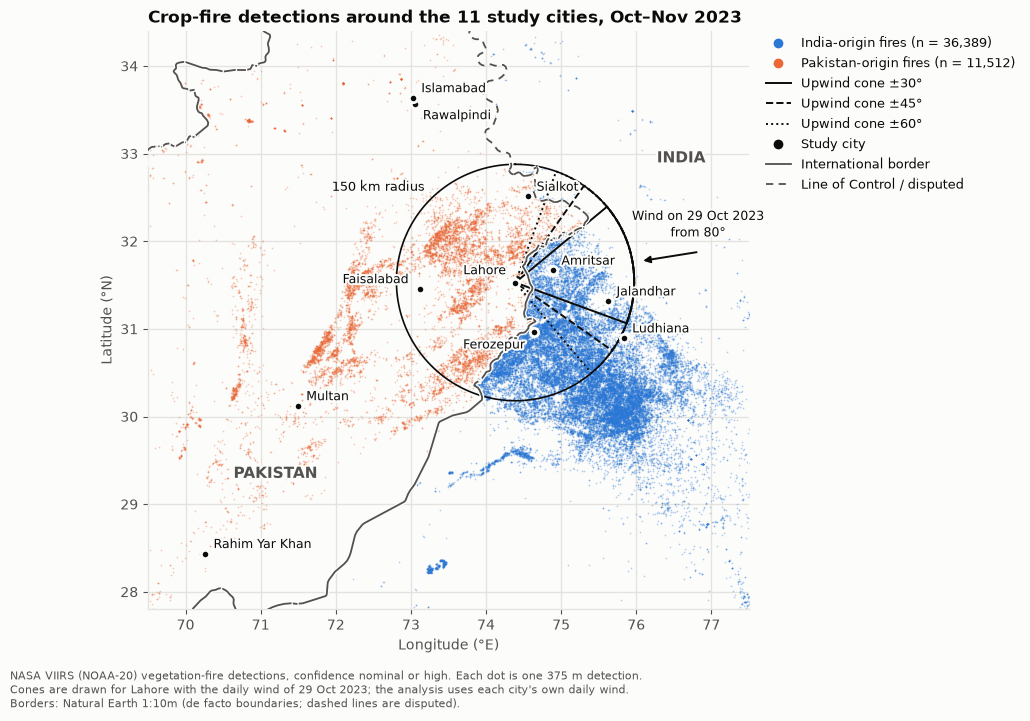

In [17]:
# Figure 1: study area. Fires of the 2023 rice-burning season, the 11 cities,
# Lahore's 150 km radius, and the three cone widths for one example wind direction.
season = fires[(fires["date"] >= "2023-10-01") & (fires["date"] <= "2023-11-30")]
# Example cone: the Oct-Nov 2023 day (not stagnant) with the most India-origin fires in Lahore's 45 degree cone
EXAMPLE_CITY = "Lahore"
lahore_days = fire_wide[(fire_wide["city"] == EXAMPLE_CITY) & (fire_wide["stagnant"] == 0)
                        & fire_wide["date"].between("2023-10-01", "2023-11-30")]
EXAMPLE_DAY = lahore_days.loc[lahore_days["fire_cnt_up45_r150_in"].idxmax(), "date"]
EXAMPLE_WIND_FROM = float(wind.set_index(["city", "date"]).loc[(EXAMPLE_CITY, EXAMPLE_DAY), "wind_dir_from_deg"])
print(f"Example day: {EXAMPLE_DAY:%d %b %Y}, wind from {EXAMPLE_WIND_FROM:.0f} degrees")

fig, ax = plt.subplots(figsize=(10.5, 7.2))
for origin in ["PK", "IN"]:
    pts = season[season["origin_country"] == origin]
    ax.scatter(pts["longitude"], pts["latitude"], s=1.5, color=ORIGIN_COLOR[origin],
               alpha=0.35, linewidths=0, rasterized=True)

# Country borders: Natural Earth 1:10m boundary lines, clipped to the study area (Dataset/NaturalEarth).
# International borders solid; the Line of Control and other disputed or indefinite lines dashed.
import json
borders = json.load(open(ROOT / "Dataset" / "NaturalEarth" / "ne_10m_boundary_lines_study_area.geojson"))
for feature in borders["features"]:
    disputed = not feature["properties"]["featurecla"].startswith("International")
    for line in feature["geometry"]["coordinates"]:
        xy = np.array(line)
        ax.plot(xy[:, 0], xy[:, 1], color=TEXT_2, lw=1.3, ls=(0, (4, 3)) if disputed else "-",
                zorder=4, path_effects=[patheffects.withStroke(linewidth=3.2, foreground=SURFACE)])
for name, (lo, la) in {"PAKISTAN": (71.2, 29.3), "INDIA": (76.6, 32.9)}.items():
    ax.text(lo, la, name, fontsize=11, color=TEXT_2, ha="center", fontweight="bold", zorder=6, path_effects=halo)

clat, clon = CITY_COORDS[EXAMPLE_CITY]
ring = np.array([destination(clat, clon, b, 150) for b in np.arange(0, 361, 2)])
ax.plot(ring[:, 1], ring[:, 0], color=TEXT, lw=1.2)
ring_label_at = destination(clat, clon, 315, 150)
ax.annotate("150 km radius", xy=ring_label_at[::-1], xytext=(-4, 4), textcoords="offset points",
            color=TEXT, fontsize=9, ha="right", va="bottom")

for half, ls in [(30, "-"), (45, "--"), (60, ":")]:
    arc = np.array([destination(clat, clon, b, 150)
                    for b in np.linspace(EXAMPLE_WIND_FROM - half, EXAMPLE_WIND_FROM + half, 40)])
    wedge = np.vstack([[clat, clon], arc, [clat, clon]])
    ax.plot(wedge[:, 1], wedge[:, 0], color=TEXT, lw=1.4, ls=ls)
arrow_start = destination(clat, clon, EXAMPLE_WIND_FROM, 235)
ax.annotate("", xy=destination(clat, clon, EXAMPLE_WIND_FROM, 160)[::-1], xytext=arrow_start[::-1],
            arrowprops=dict(arrowstyle="-|>", color=TEXT, lw=1.4))
ax.annotate(f"Wind on {EXAMPLE_DAY:%d %b %Y}\nfrom {EXAMPLE_WIND_FROM:.0f}°", xy=arrow_start[::-1], xytext=(0, 8),
            textcoords="offset points", fontsize=9, color=TEXT, ha="center", va="bottom", path_effects=halo)

# label position per city (offset in points, alignment) so neighbouring names don't overlap
LABEL_POS = {"Islamabad": ((6, 4), "left"), "Rawalpindi": ((6, -11), "left"), "Lahore": ((-6, 6), "right"), "Faisalabad": ((-6, 4), "right"),
             "Amritsar": ((6, 4), "left"), "Ferozepur": ((-6, -12), "right"), "Jalandhar": ((6, 4), "left"),
             "Ludhiana": ((6, 4), "left")}
for city, (la, lo) in CITY_COORDS.items():
    ax.scatter(lo, la, s=36, color=TEXT, edgecolors=SURFACE, linewidths=2, zorder=5)
    offset, ha = LABEL_POS.get(city, ((6, 4), "left"))
    ax.annotate(city, (lo, la), xytext=offset, textcoords="offset points", fontsize=9, ha=ha,
                color=TEXT, zorder=6, path_effects=halo)

ax.set_xlim(69.5, 77.5); ax.set_ylim(27.8, 34.4)
ax.set_aspect(1 / np.cos(np.radians(31)))           # keeps distances true at Punjab's latitude
ax.set_xlabel("Longitude (°E)"); ax.set_ylabel("Latitude (°N)")
ax.grid(True, zorder=0); ax.set_axisbelow(True)
ax.set_title("Crop-fire detections around the 11 study cities, Oct–Nov 2023", loc="left")

handles = [Line2D([], [], ls="", marker="o", ms=6, color=ORIGIN_COLOR[o],
                  label=f"{ORIGIN_LABEL[o]} (n = {(season['origin_country'] == o).sum():,})") for o in ["IN", "PK"]]
handles += [Line2D([], [], color=TEXT, lw=1.4, ls=ls, label=f"Upwind cone ±{h}°") for h, ls in [(30, "-"), (45, "--"), (60, ":")]]
handles += [Line2D([], [], ls="", marker="o", ms=6, color=TEXT, label="Study city"),
            Line2D([], [], color=TEXT_2, lw=1.3, label="International border"),
            Line2D([], [], color=TEXT_2, lw=1.3, ls=(0, (4, 3)), label="Line of Control / disputed")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.02, 1), fontsize=9, borderaxespad=0)
fig.text(0.01, 0.005,
         "NASA VIIRS (NOAA-20) vegetation-fire detections, confidence nominal or high. Each dot is one 375 m detection.\n"
         f"Cones are drawn for Lahore with the daily wind of {EXAMPLE_DAY:%d %b %Y}; the analysis uses each city's own daily wind.\n"
         "Borders: Natural Earth 1:10m (de facto boundaries; dashed lines are disputed).",
         fontsize=8, color=TEXT_2, va="bottom")
fig.tight_layout(rect=(0, 0.065, 1, 1))
fig.savefig(FIG_DIR / "fig_fire_study_area.png", dpi=200)
plt.show()

**Figure 1. Crop-fire detections around the 11 study cities, October–November 2023.**
Each dot is one NASA VIIRS (NOAA-20) vegetation-fire detection with nominal or high confidence. Blue = detections in India, orange = detections in Pakistan.
Grey lines are country borders from Natural Earth 1:10m (de facto boundaries). The Line of Control and other disputed lines are dashed. The clipped border file is stored in `Dataset/NaturalEarth/`, so the notebook needs no internet. The border runs exactly where the blue and orange dots meet, which confirms that labelling fires by source file (India or Pakistan) is correct.
The circle is the 150 km default radius around Lahore. The three wedges are the ±30°, ±45° and ±60° upwind cones for Lahore on one real day: the October–November 2023 day (not stagnant) with the most India-origin fires inside Lahore's ±45° cone, using that day's wind from Person B's table. The date and wind direction are printed above the figure. The analysis itself uses each city's own daily wind.
The dense Indian Punjab burning belt lies east and south-east of Lahore and Sialkot and largely outside 150 km of Multan and Rahim Yar Khan. That is why the cross-border effect can only be tested for the cities nearest the border.
Saved as `figures/fig_fire_study_area.png`.

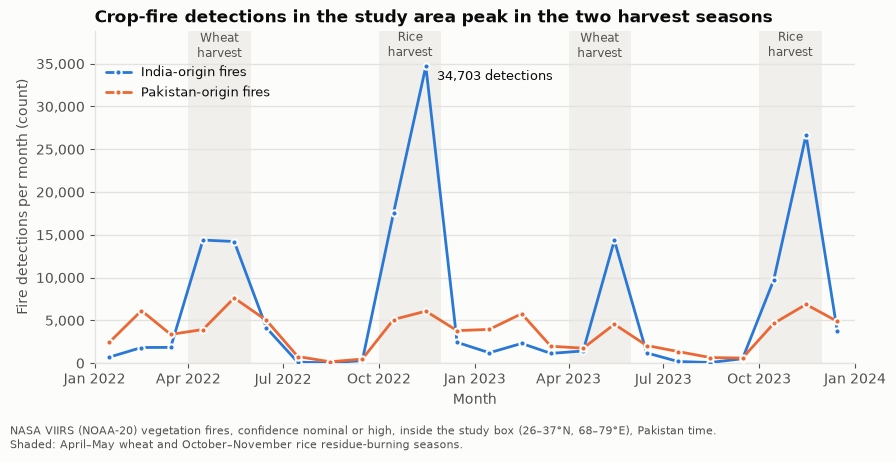

In [18]:
# Figure 2: monthly fire detections in the study area, by country of origin.
monthly = (fires.groupby([fires["date"].dt.to_period("M"), "origin_country"]).size()
           .unstack(fill_value=0).reindex(pd.period_range("2022-01", "2023-12", freq="M"), fill_value=0))
x = monthly.index.to_timestamp() + pd.Timedelta(days=14)     # plot at mid-month

fig, ax = plt.subplots(figsize=(9, 4.6))
for start in ["2022-10-01", "2023-10-01"]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(start) + pd.offsets.MonthEnd(2), color=BAND, zorder=0, lw=0)
for start in ["2022-04-01", "2023-04-01"]:
    ax.axvspan(pd.Timestamp(start), pd.Timestamp(start) + pd.offsets.MonthEnd(2), color=BAND, zorder=0, lw=0)
for origin in ["IN", "PK"]:
    ax.plot(x, monthly[origin], color=ORIGIN_COLOR[origin], lw=2, solid_capstyle="round",
            solid_joinstyle="round", marker="o", ms=4.5, mec=SURFACE, mew=1.5, label=ORIGIN_LABEL[origin], zorder=3)

peak = monthly["IN"].idxmax()
ax.annotate(f"{monthly['IN'].max():,} detections", (peak.to_timestamp() + pd.Timedelta(days=14), monthly["IN"].max()),
            xytext=(8, -2), textcoords="offset points", fontsize=9, color=TEXT, va="top")
ymax = monthly.values.max() * 1.12
for start, label in [("2022-04-01", "Wheat\nharvest"), ("2022-10-01", "Rice\nharvest"),
                     ("2023-04-01", "Wheat\nharvest"), ("2023-10-01", "Rice\nharvest")]:
    ax.text(pd.Timestamp(start) + pd.Timedelta(days=30), ymax, label, ha="center", va="top", fontsize=8.5, color=TEXT_2)

ax.set_ylim(0, ymax)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:,.0f}"))
ax.grid(axis="y"); ax.set_axisbelow(True)
ax.set_ylabel("Fire detections per month (count)")
ax.set_xlabel("Month")
ax.set_xlim(pd.Timestamp("2022-01-01"), pd.Timestamp("2024-01-01"))
ax.xaxis.set_major_locator(mdates.MonthLocator(bymonth=[1, 4, 7, 10]))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.set_title("Crop-fire detections in the study area peak in the two harvest seasons", loc="left")
ax.legend(loc="upper left", bbox_to_anchor=(0, 0.93), fontsize=9)
fig.text(0.01, 0.005,
         "NASA VIIRS (NOAA-20) vegetation fires, confidence nominal or high, inside the study box (26–37°N, 68–79°E), Pakistan time.\n"
         "Shaded: April–May wheat and October–November rice residue-burning seasons.",
         fontsize=8, color=TEXT_2, va="bottom")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIG_DIR / "fig_fire_monthly_by_origin.png", dpi=200)
plt.show()

**Figure 2. Monthly crop-fire detections in the study area by country of origin, 2022–2023.**
Same filters as Figure 1, inside the study box (26–37°N, 68–79°E), with months in Pakistan time.
India-origin detections dominate both harvest seasons: the wheat-residue burn in April–May and, much larger, the rice-residue burn in October–November, peaking at 34,703 detections in November 2022.
Pakistan-origin detections follow the same seasons at a lower level.
The October–November peak coincides with the start of the winter smog season, so fire counts and smog will rise together for seasonal reasons alone. This is why the cone analysis compares upwind with downwind fires.
Saved as `figures/fig_fire_monthly_by_origin.png`.

#### Step 16: Save and final checks

In [19]:
points_out = fires_nhl[["date", "time_utc", "time_local", "latitude", "longitude", "origin_country", "frp",
                        "confidence", "conf_high", "conf_low", "daynight", "is_night", "bright_ti4",
                        "bright_ti5", "scan", "track", "source_file"]]
points_out.to_csv(OUT_DIR / "fire_points_clean.csv", index=False)
fire_long.to_csv(OUT_DIR / "fire_city_day_long.csv", index=False)
fire_wide.to_csv(OUT_DIR / "fire_city_day_wide.csv", index=False)
pd.DataFrame(audit).to_csv(OUT_DIR / "fire_filter_audit.csv", index=False)

# clean tables for the merge, next to the AQ and weather tables
import json
CLEAN_DIR = ROOT / "Dataset" / "clean"
fire_wide.to_parquet(CLEAN_DIR / "fire_daily.parquet", index=False)
fire_long.to_parquet(CLEAN_DIR / "fire_daily_long.parquet", index=False)
with open(CLEAN_DIR / "fire_zscore_params.json", "w") as f:
    json.dump(zparams, f, indent=2)

print("Saved to", OUT_DIR.relative_to(ROOT), "and", CLEAN_DIR.relative_to(ROOT))
print("Cities:", fire_wide["city"].nunique(), "| rows:", len(fire_wide),
      "| duplicate city+date:", fire_wide.duplicated(["city", "date"]).sum())
radius_cols = [c for c in fire_wide if c.startswith("fire_") and "up45" not in c and "down45" not in c]
cone_cols = [c for c in fire_wide if "up45" in c or "down45" in c]
print("Missing values: radius columns", int(fire_wide[radius_cols].isna().sum().sum()),
      "| each cone column", fire_wide[cone_cols].isna().sum().unique().tolist(),
      "(January 2022 days without wind) | stagnant", int(fire_wide["stagnant"].isna().sum()))
print("Date range:", fire_wide["date"].min().date(), "to", fire_wide["date"].max().date())
on = fire_wide[fire_wide["date"].dt.month.isin([10, 11])]
print("\nShare of Oct-Nov days with at least one fire within 150 km (any origin):")
print((on.groupby("city")["fire_cnt_r150_all"].apply(lambda s: (s > 0).mean())).round(2).reindex(CITIES))
print("\nFilter audit:")
print(pd.DataFrame(audit).to_string(index=False))

Saved to Dataset/Exported_Fire and Dataset/clean
Cities: 11 | rows: 8030 | duplicate city+date: 0
Missing values: radius columns 0 | each cone column [178] (January 2022 days without wind) | stagnant 178
Date range: 2022-01-01 to 2023-12-31

Share of Oct-Nov days with at least one fire within 150 km (any origin):
city
Lahore            0.98
Faisalabad        0.98
Multan            0.99
Rawalpindi        0.86
Sialkot           0.96
Rahim Yar Khan    0.84
Islamabad         0.87
Amritsar          0.97
Ferozepur         0.98
Ludhiana          0.97
Jalandhar         0.96
Name: fire_cnt_r150_all, dtype: float64

Filter audit:
                                          step  rows_before  rows_after  removed                                            note
                 Bounding box 26-37 N, 68-79 E      1284773      287323   997450                                                
                 Keep type 0 (vegetation fire)       287323      279968     7355 drops type 2 static sources and t

**Saved files** (in `Dataset/Exported_Fire/`, not uploaded to GitHub):
- `fire_points_clean.csv`: every type 0 point in the study area, all confidence levels, with the 0/1 dummy columns. Filter on `confidence` to get any version.
- `fire_city_day_long.csv`: every setting, one row per city, day, cone, radius and origin.
- `fire_city_day_wide.csv`: the default setting, one row per city per day (8,030 rows), ready for the merge.
- `fire_filter_audit.csv`: rows before and after each filter (copied into `DECISIONS.md`).

**Clean tables for the merge** (in `Dataset/clean/`, uploaded to GitHub like the weather tables):
- `fire_daily.parquet`: the wide table with the log1p and z-score columns and the outlier flags. This is the file to merge with AQ and weather on `city` + `date`.
- `fire_daily_long.parquet`: the long table with every cone, radius and origin, for the sensitivity analysis.
- `fire_zscore_params.json`: training-period mean and SD for each z-scored column.

The checks confirm 11 cities, no duplicate city-days, and the full 2022-2023 date range. Radius columns have no missing values. Cone columns and `stagnant` are empty only on the 178 January 2022 city-days without wind data, all before the modelling window.